# ContextNet + NicheNet Workflow

This tutorial demonstrates how to create publication-ready Sankey diagrams from **ContextNet/NicheNet** cell-cell communication analysis results using ccflowR.

### What You'll Learn

1. Load NicheNet output data into ccflowR
2. Define consistent cell type colors
3. Create a basic Sankey plot
4. Customize your figure for publication (coloring, highlighting, ordering)
5. Export figures

For detailed parameter reference (every option with visual side-by-side comparisons), see the **Parameter Reference Guide**.

### How ccflowR Fits in the ContextNet Pipeline

    ┌─────────────────────┐     ┌─────────────────┐     ┌─────────────┐
    │ GRN Inference       │────>│ ContextNet      │────>│ ccflowR     │
    │ (Snakemake)         │     │ (R package)     │     │ (Sankey)    │
    │                     │     │                 │     │             │
    │ scRNA + scATAC      │     │ GRN + NicheNet  │     │ Visualize   │
    │ → TF-target GRN     │     │ → Ligand scores │     │ → Figures   │
    └─────────────────────┘     └─────────────────┘     └─────────────┘
                                    │
                                    v
                              sankey_river.csv

ccflowR visualizes the signaling flow as: **Sender Cell → Ligand → Receptor → Receiver Cell**

## Data Requirements

### Required Columns
| Column | Type | Description |
|--------|------|-------------|
| `sender` | character | Sending cell type name |
| `receiver` | character | Receiving cell type name |
| `ligand` | character | Ligand gene symbol |
| `receptor` | character | Receptor gene symbol (optional -- omit with `receptor_col = NULL` for 3-layer plots) |

ContextNet's `prepare_for_ccflowr()` produces all required columns including expression weights (`scaled_activity`, `scaled_ligand_expression`, `scaled_receptor_expression`) that enable edge thickness to reflect biological signal strength.

### Loading Your Own Data

    # Load your NicheNet/ContextNet output file
    data <- read_nichenet("path/to/your/sankey_river.csv")
    head(data)


In [1]:
library(ccflowR)

# Static display helper (renders PNG for GitHub compatibility)
# Re-run notebook locally for interactive plots
show <- function(p, width = 600, height = 900) {
  tmpfile <- tempfile(fileext = ".png")
  sankey_save(p, tmpfile, width = width, height = height)
  IRdisplay::display_png(file = tmpfile)
  invisible(p)
}

ccflowR v0.1.0 - Cell-Cell Communication Flow Visualization



## Step 1: Load Data

**Why start here?** Before any visualization, you need to verify that your data loaded correctly and contains the expected columns. Inspecting the data early catches formatting issues before they cause cryptic errors downstream.

In [2]:
# Use example data for demonstration
ex <- example_communication()
data <- ex$data

# Inspect the data structure
head(data)

,sender,receiver,ligand,receptor,activity,scaled_activity,scaled_receptor_expression
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,Macrophage,T_cell,TGFB1,TGFBR1,0.90,0.92,0.40
2,Fibroblast,Endothelial,TGFB1,TGFBR1,0.52,0.55,0.85
3,Macrophage,Fibroblast,TNF,TNFRSF1A,0.82,0.85,0.30
4,T_cell,Macrophage,TNF,TNFRSF1A,0.40,0.42,0.75
5,Macrophage,T_cell,IL6,IL6R,0.75,0.78,0.90
6,Fibroblast,B_cell,IL6,IL6R,0.33,0.35,0.60


**Why summarize?** `summarize_data()` gives a quick overview of your network: how many interactions, cell types, ligands, and receptors. This is the fastest way to check that no data was lost during import and that column names mapped correctly.

In [3]:
# Get a summary of the communication data
summarize_data(data)

$n_interactions
[1] 15

$n_senders
[1] 5

$n_receivers
[1] 5

$n_ligands
[1] 11

$n_receptors
[1] 11

$senders
[1] "Macrophage"  "Fibroblast"  "T_cell"      "Endothelial" "B_cell"     

$receivers
[1] "T_cell"      "Endothelial" "Fibroblast"  "Macrophage"  "B_cell"     

$ligands
 [1] "TGFB1"  "TNF"    "IL6"    "IFNG"   "VEGFA"  "PDGFB"  "IL2"    "IL4"   
 [9] "CCL2"   "CXCL12" "IL10"  

$receptors
 [1] "TGFBR1"   "TNFRSF1A" "IL6R"     "IFNGR1"   "KDR"      "PDGFRB"  
 [7] "IL2RA"    "IL4R"     "CCR2"     "CXCR4"    "IL10R"

You should see 15 interactions involving 5 cell types (Macrophage, T_cell, B_cell, Fibroblast, Endothelial) with 11 unique ligands and 11 unique receptors. Notice that some ligands (TGFB1, TNF, IL6) are produced by multiple senders, and some receptors (TGFBR1, TNFRSF1A, IL6R, IFNGR1) appear on multiple receivers — these shared nodes create convergence and divergence patterns in the Sankey diagram.

## Step 2: Define Cell Type Colors

**Why define colors explicitly?** When generating multiple figures for a paper or presentation, using the same color for each cell type across all panels makes it easier for readers to track cell types at a glance.

In [4]:
# Use colors from the example data
celltype_colors <- ex$colors

# View the color assignments
print(celltype_colors)

# Verify all cell types in data have colors assigned
all_celltypes <- get_all_celltypes(data)
missing <- setdiff(all_celltypes, names(celltype_colors))
if (length(missing) > 0) {
  cat("Warning: No colors defined for:", paste(missing, collapse = ", "), "\n")
} else {
  cat("All cell types have colors assigned\n")
}

 Macrophage      T_cell  Fibroblast Endothelial      B_cell 
  "#E41A1C"   "#377EB8"   "#4DAF4A"   "#984EA3"   "#FF7F00" 


All cell types have colors assigned


## Step 3: Create Your First Sankey Plot

**Why start with a basic plot?** Before customizing, verify that your data loaded correctly and get an overview of the communication network. The default plot shows all interactions with sensible defaults.

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b5fe1d3bd.png



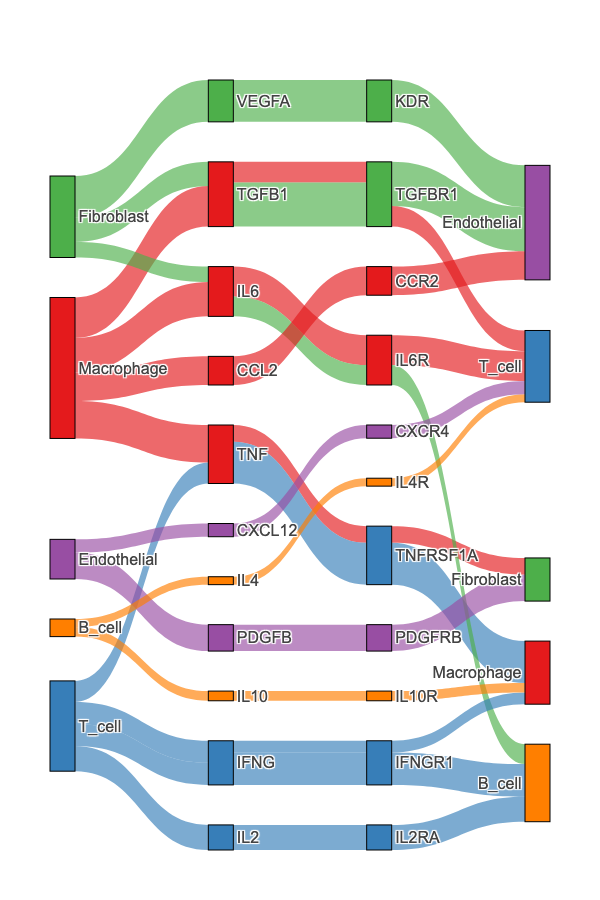

In [5]:
# Basic plot — edge thickness reflects expression levels, colored by sender
p <- sankey_plot(data, celltype_colors)
show(p)

The plot displays four layers from left to right:
1. **Sender** (left) - Cell types sending signals
2. **Ligand** (center-left) - Signaling molecules
3. **Receptor** (center-right) - Receptor molecules
4. **Receiver** (right) - Cell types receiving signals

Edge thickness reflects expression levels — thicker edges represent stronger interactions. Nodes are automatically ordered to minimize link crossings.

> **Tip:** Set `receptor_col = NULL` in `sankey_plot()` to create a simpler 3-layer diagram (Sender -> Ligand -> Receiver) when receptor information is not needed.

## Step 4: Customize Your Figure

ccflowR uses a `+` operator to layer customizations. Below are the most common adjustments for NicheNet data. See the **Parameter Reference Guide** for exhaustive visual examples of every parameter.

### Coloring Strategies

Color flows by `"sender"` (default), `"receiver"`, or `"ligand"` to answer different biological questions.

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b3f313d37.png



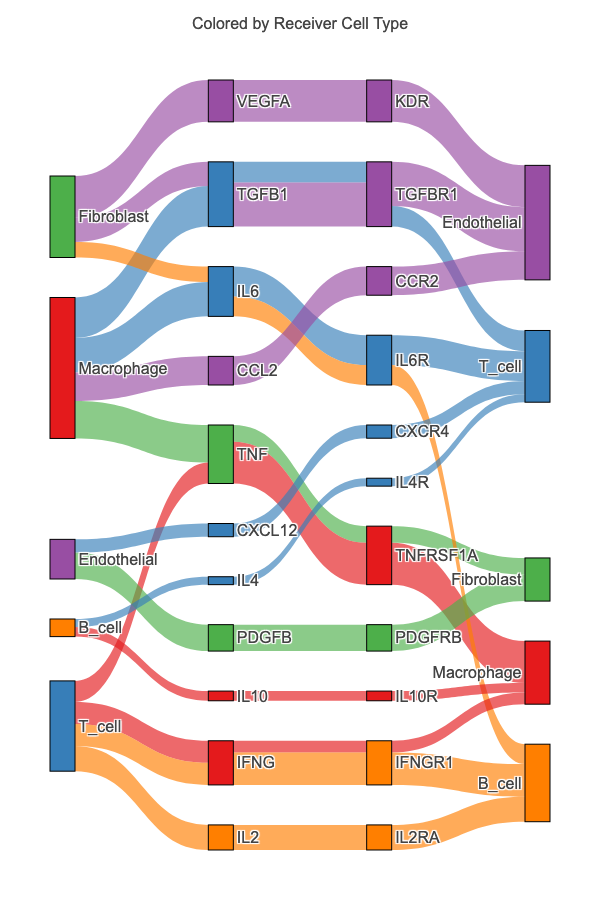

In [6]:
# Color by receiver — "Who is receiving the most signals?"
p <- sankey_plot(data, celltype_colors) +
  sankey_colors(by = "receiver") +
  sankey_title("Colored by Receiver Cell Type")
show(p)

### Uniform Mode (Optional)

By default, edge thickness reflects expression levels. If you only want to show which cell types communicate (ignoring signal strength), use uniform mode.

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b3ef51ae5.png



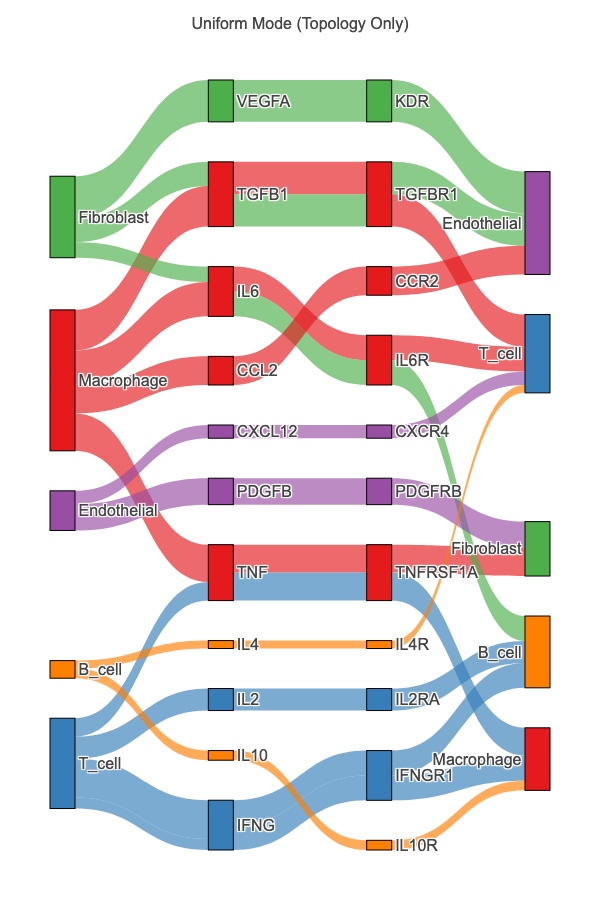

In [7]:
# Show network topology only (all edges equal thickness)
p <- sankey_plot(data, celltype_colors, flow = "uniform") +
  sankey_title("Uniform Mode (Topology Only)")
show(p)

### Highlighting Pathways

Use `sankey_highlight()` to focus attention on specific pathways while keeping the full network visible for context. You can highlight by `senders`, `receivers`, `ligands`, or `receptors` (multiple criteria use AND logic). See the **Parameter Reference Guide** for all highlighting options and `dim_alpha` variations.

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b4a1105aa.png



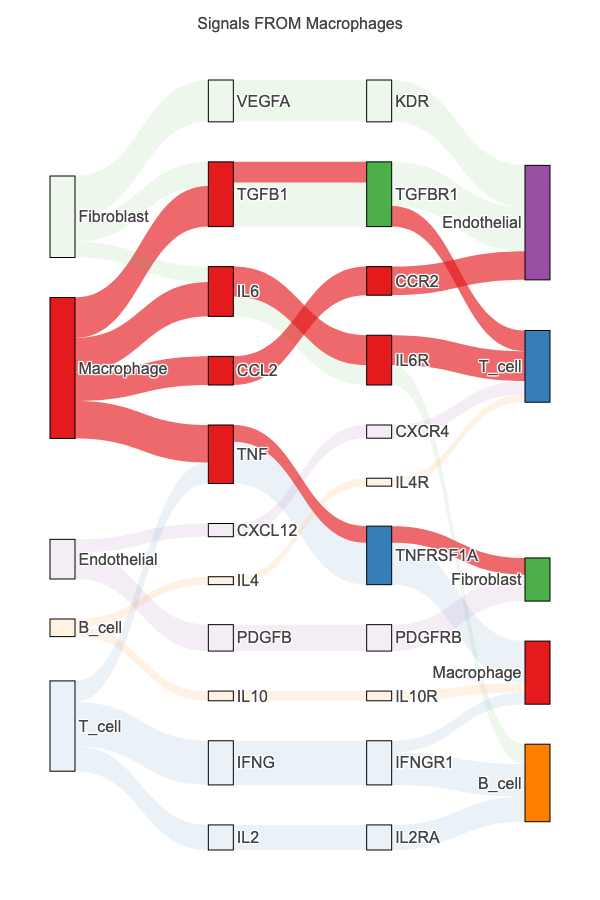

In [8]:
# Focus on signals FROM Macrophages
p <- sankey_plot(data, celltype_colors) +
  sankey_highlight(senders = "Macrophage", dim_alpha = 0.1) +
  sankey_title("Signals FROM Macrophages")
show(p)

### Custom Node Ordering

By default, nodes are ordered using a barycenter heuristic that minimizes link crossings. Use `sankey_order()` to override with a custom arrangement based on biological narrative (e.g., differentiation stage, immune cell hierarchy).

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b2cb1360a.png



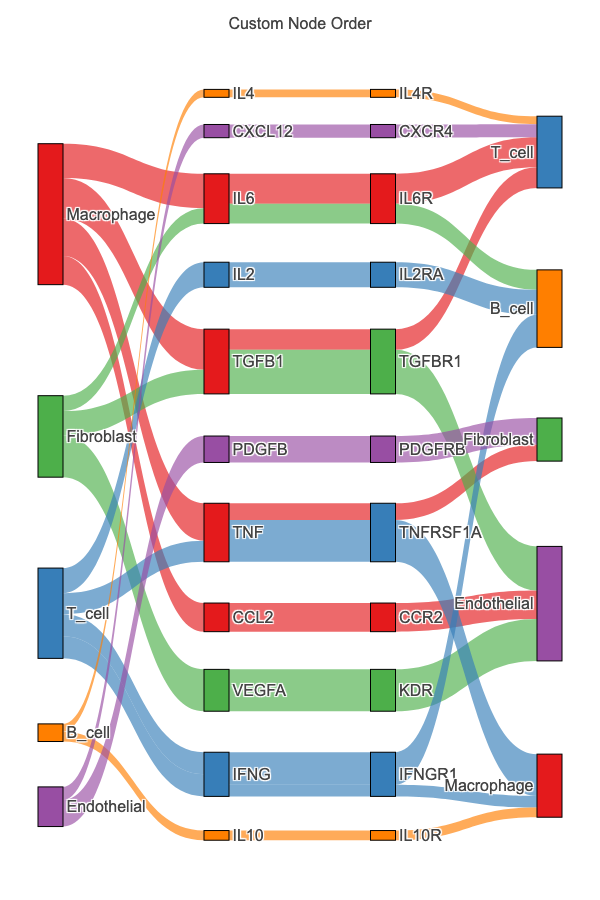

In [9]:
p <- sankey_plot(data, celltype_colors) +
  sankey_order(
    senders = c("Macrophage", "Fibroblast", "T_cell", "B_cell", "Endothelial"),
    receivers = c("T_cell", "B_cell", "Fibroblast", "Endothelial", "Macrophage")
  ) +
  sankey_title("Custom Node Order")
show(p)

### 3-Layer Mode (No Receptor)

When your analysis focuses on ligand-target cell relationships without explicit receptor data, omit the receptor layer for a cleaner visualization.

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



No receptor layer: falling back to uniform flow method



Saved static image to: /var/folders/65/8q5_78px5cj915lqjn_zldkm0000gp/T//RtmphXLJzQ/file946b775817b2.png



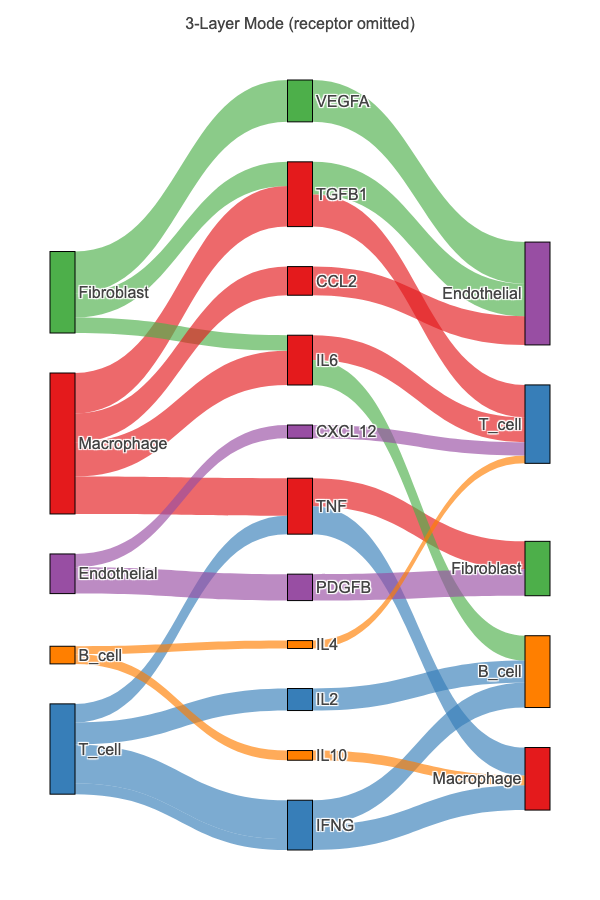

In [10]:
# 3-layer Sankey: Sender -> Ligand -> Receiver
p <- sankey_plot(data, celltype_colors, receptor_col = NULL) +
  sankey_title("3-Layer Mode (receptor omitted)")
show(p)

## Step 5: Export

Save your figure as HTML (interactive) or static formats (PNG, PDF, SVG). See the **Parameter Reference Guide** for all export options and format details.

In [11]:
# Build a publication-ready figure
p <- sankey_plot(data, celltype_colors) +
  sankey_colors(by = "receiver") +
  sankey_highlight(senders = "Macrophage") +
  sankey_alpha(0.6) +
  sankey_title("Macrophage Signaling Network")

# Save as interactive HTML (always works, no dependencies)
sankey_save(p, "example_output.html")
cat("Saved HTML\n")

# Save as static PNG (requires kaleido or webshot2)
# sankey_save(p, "example_output.png", width = 700, height = 900)

# Clean up
if (file.exists("example_output.html")) file.remove("example_output.html")

NicheNet: Set scaled_ligand_expression = scaled_activity (combined score)



Warning message in dir.create(target_dir):
“'example_output_files/htmlwidgets-1.6.4' already exists”


Warning message in file.create(to[okay]):
“cannot create file 'example_output_files/plotly-binding-4.12.0/plotly.js', reason 'No such file or directory'”


Saved interactive HTML to: example_output.html



Saved HTML


[1] TRUE

## Complete Workflow

    library(ccflowR)

    # 1. Load your NicheNet/ContextNet output
    data <- read_nichenet("path/to/your/sankey_river.csv")
    summarize_data(data)

    # 2. Define cell type colors
    celltype_colors <- c(
      "B Cell" = "#17BECF", "T Cell" = "#006837",
      "Myeloid" = "#FF7F0E", "Fibroblast" = "#9C46D3",
      "Epithelial" = "#1F77B4", "Endothelial" = "#E89FBD"
    )

    # 3. Create and customize figure
    p <- sankey_plot(data, celltype_colors) +
      sankey_colors(by = "receiver") +
      sankey_highlight(senders = "Macrophage") +
      sankey_alpha(0.6) +
      sankey_title("Cell-Cell Communication")

    # 4. Save (see Parameter Reference Guide for all export options)
    sankey_save(p, "Figure1.html")
    sankey_save(p, "Figure1.png", width = 700, height = 900)

## Troubleshooting

| Issue | Solution |
|-------|----------|
| "Missing required columns" | Check column names: `sender`, `receiver`, `ligand`, `receptor` |
| "Falling back to uniform" | Add `scaled_activity` and `scaled_receptor_expression` columns |
| Plot not displaying | Re-run the cell (known htmlwidget issue) |
| Colors not applied | Ensure color vector names match cell type names exactly (case-sensitive) |
| SVG export fails | Install kaleido: `reticulate::py_install("kaleido")` |

## Next Steps
- **Multi-condition analysis**: See the MultiNicheNet tutorial
- **All parameters**: See the Parameter Reference Guide